# Prototype Comparison Based on Key Metrics

**Objective**  
Compare Flow A (no button) and Flow B (with button) across key evaluation metrics and formulate recommendations on which variant to advance to the production A/B test.

**Agenda**
1. Setup and Data Ingestion
2. Target Feature Extraction
3. Primary Metric: Discount Noticeability
4. Deep Dive: Comprehension of Repeat-Use Rules
5. Diagnostic Evaluation: Offer Appeal
6. Strategic Recommendations & A/B Test Hypotheses

###  1. Setup and Data Ingestion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from scipy import stats
import pingouin as pg
import statsmodels.stats.proportion as smprop

In [2]:
# display settings for high-dimensional dataset
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 50)

In [3]:
# Load the dataset. Low_memory = False handles mixed types across columns
DATA_PATH = '../data/P1_FTD_cleaned_sample.csv'
df = pd.read_csv(DATA_PATH, low_memory = False)
print(f"Cleaned dataset loaded: {df.shape[0]} sessions, {df.shape[1]} columns")

Cleaned dataset loaded: 198 sessions, 175 columns


### 2. Target Feature Extraction

Further analysis focuses on the following target dimensions and survey variables:

**Primary Metric: Discount Noticeability**
- **Applied Discount Noticeability (Current):**  
  Multi-select prompt: `'Q14. Did you notice any of the following during the deposit process? Select all that apply. A discount was applied'`
- **Future Discount Noticeability (Retention Hook):**  
  Multi-select prompt: `'Q18. Did you notice any of the following additional details during the deposit process? Select all that apply. A discount was promised for future payments'`

**Deep Dive: Comprehension of Repeat-Use Rules**
- **Payment Method Attribution.** Did users link the discount specifically to the payment method?  
  Single-select: `'Q22. How do you think the future discount will be given? Answer'`  
  *Target answer:* `'The discount will be given only if the same payment method is used'`
- **Time Constraint Awareness.** Did users recognize the 7-day redemption window?  
  Single-select: `'Q20. To which payments will this future discount be applied? Answer'`  
  *Target answer:* `'It will apply only if a payment is made within a specific period'`  
  Open-ended numeric: `'Q21. Within how many days should the next payment be made for the discount to apply? (Please enter the number of the days) Answer'`  
  *Target answer:* `7` (answers `<= 7 days` are accepted as valid retention window awareness, since a shorter perceived deadline maintains urgency, whereas values `> 7 days` miss the offer condition).
- **Discount Magnitude Recall.** Did users recall the exact incentive size (1%)?  
  Open-ended numeric: `'Q19. You noticed that a discount was promised for future payments. What was the amount of the discount promised? (Please specify the amount in %) Answer'`  
  *Target answer:* `1` or `1%`

**Diagnostic Evaluation: Offer Appeal**
- **Declared Intent to Switch Payment Method:**  
  Single-select: `'Q28. So, a 1% discount was applied to your current deposit, and a 1% discount was also promised on future deposits if they are made within 7 days using the same payment method. If you noticed this, would you make your next deposit using this payment method instead of your usual one? Answer'`  
  *Target answers:* `'Definitely yes, I would switch to this payment method'` / `'Probably yes, I would consider using this payment method'`
- **Declared Willingness to Deposit Within 7 Days:**  
  Single-select: `'Q30. Would you make a special effort to make your next deposit within 7 days to receive this 1% discount? Answer'`  
  *Target answer:* `'Yes'`
- **Historical Responsiveness to Time-Limited Offers (benchmark):**  
  Single-select: `'Q32. Think back to the last time an online investment, crypto, or trading platform offered you a limited-time bonus or discount if you acted within a certain time. Did you do it in time to get the bonus/discount? Answer'`  
  *Target answer:* `'Yes, I did it in time to get the bonus/discount'`

In [4]:
#function to extract col names using prefix ans substring 
def col_extractor (prefix: str = '', substring: str = ''):
    match = [c for c in df.columns if c.lower().startswith (prefix.lower()) and substring.lower() in c.lower()]
    if len (match) > 1:
        raise ValueError (f'Multiple matches for {prefix} and {substring}: {match}')
    elif not match:
        raise KeyError (f'Nothing found for {prefix} and {substring}')
    return match[0]


#map short feature name  -> (prefix, substring)
FEATURE_SCHEMA = {
    #Primary Metric: Discount Noticeability*
    "applied_discount_noticed": ("Q14.", "A discount was applied"),
    "future_discount_noticed": ("Q18.", "A discount was promised for future payments"),

    #Deep Dive: Comprehension of Repeat-Use Rules
    "method_attribution": ("Q22.", ""),
    "time_constraint_aware": ("Q20.", ""),
    "time_constraint_days": ("Q21.", ""),
    "discount_magnitude_recalled": ("Q19.", "(Please specify the amount in %) Answer"),

    #Diagnostic Evaluation: Offer Appeal
    "intent_to_switch": ("Q28.", ""),
    "willingness_to_deposit_7d": ("Q30.", ""),
    "historical_promo_usage": ("Q32.", ""),

    #technical cols
    "flow": ("flow", ""),
    "age": ("age", ""),
    "gender": ("Q3.", "gender"),
}

#building dict long feature name ->  short feature name
long_short_names_mapped = {col_extractor(prefix, substring): short_name for short_name, (prefix, substring) in FEATURE_SCHEMA.items()}

#print final mapping to double-check 
for key, value in long_short_names_mapped.items():
    print (key,"\n/", value, '/\n')

Q14. Did you notice any of the following during the deposit process?
Select all that apply. A discount was applied 
/ applied_discount_noticed /

Q18. Did you notice any of the following additional details during the deposit process?
Select all that apply. A discount was promised for future payments 
/ future_discount_noticed /

Q22. How do you think the future discount will be given? Answer 
/ method_attribution /

Q20. To which payments will this future discount be applied? Answer 
/ time_constraint_aware /

Q21. Within how many days should the next payment be made for the discount to apply? (Please enter the number of the days) Answer 
/ time_constraint_days /

Q19. You noticed that a discount was promised for future payments. 
What was the amount of the discount promised? (Please specify the amount in %) Answer 
/ discount_magnitude_recalled /

Q28. So, a 1% discount was applied to your current deposit, and a 1% discount was also promised on future deposits if they are made within 

In [5]:
#create a dataset with selected cols only
df_extracted = df[list(long_short_names_mapped)].rename(columns = long_short_names_mapped)

print(f'rows {df_extracted.shape[0]}, columns {df_extracted.shape[1]}')
df_extracted.head(3)


rows 198, columns 12


,applied_discount_noticed,future_discount_noticed,method_attribution,time_constraint_aware,time_constraint_days,discount_magnitude_recalled,intent_to_switch,willingness_to_deposit_7d,historical_promo_usage,flow,age,gender
0,A discount was applied,NaN,NaN,NaN,NaN,NaN,"Probably yes, I would consider using this paym...",No,"No, I didn’t do it in time",Flow A (no button),34,Male
1,A discount was applied,A discount was promised for future payments,The discount will be given by the website wher...,It will apply only if a payment is made within...,7 days,1%,"Probably yes, I would consider using this paym...",No,I’ve never been offered this kind of bonus/dis...,Flow A (no button),33,Female
2,A discount was applied,NaN,NaN,NaN,NaN,NaN,"Definitely yes, I would switch to this payment...",It’s hard to say,"Yes, I did it in time to get the bonus/discount",Flow A (no button),21,Male


### 3. Primary Metric: Discount Noticeability

**Objective**  
Compare how often respondents in Flow A and Flow B noticed the future discount when prompted. Users need to notice the offer before it can encourage repeat use. 

**Analysis Plan**
1. Main analysis:
   - Future discount noticeability (`future_discount_noticed`): compare counts and percentages by flow. Report the difference, a 95% confidence interval, and a two-sided test at the 5% significance level.
   - Sensitivity analysis: check whether accounting for age and gender changes the main result.

2. Diagnostic analysis:
   - Current discount noticeability (`applied_discount_noticed`): compare the share who noticed the immediate benefit.
   - Both discounts together: compare four groups—both noticed, current only, future only, and neither to identify how often users noticed the current benefit but missed the future offer.

The next section checks whether they understood the payment method requirement and the seven-day deadline.

In [6]:
#convert target cols to boolean indicators
df_extracted['future_discount_noticed'] = df_extracted['future_discount_noticed'].notna()
df_extracted['applied_discount_noticed'] = df_extracted['applied_discount_noticed'].notna()

In [7]:
#calculate counts and percentages for the key metric - future-discount noticeability 
future_dsc_noticed_counts = pd.crosstab(df_extracted['future_discount_noticed'], df_extracted['flow'] )

future_dsc_noticed_pct = future_dsc_noticed_counts.div(future_dsc_noticed_counts.sum(axis=0), axis = 'columns').mul(100)
future_dsc_noticed_pct['delta_pp'] = future_dsc_noticed_pct['Flow A (no button)'] - future_dsc_noticed_pct['Flow B (with button)']

print('Counts')
display(future_dsc_noticed_counts)

print('Percentages')
display(future_dsc_noticed_pct.round(2))

Counts


flow,Flow A (no button),Flow B (with button)
future_discount_noticed,,
False,57,75
True,43,23


Percentages


flow,Flow A (no button),Flow B (with button),delta_pp
future_discount_noticed,,,
False,57.0,76.53,-19.53
True,43.0,23.47,19.53


Future-discount noticeability is higher in Flow A than in Flow B (43.00% vs. 23.47%), an observed difference of 19.53 percentage points.

I use a two-sided **two-proportion z-test** at a significance level of alpha = 0.05 to assess whether noticeability rates differ between the flows.м

- H0: The population noticeability rates are equal (p_A = p_B).
- H1: The population noticeability rates differ (p_A ≠ p_B).

The test assumptions are satisfied:
- The outcome is binary
- The samples are independent: each respondent tested only one flow. 

Additionally below I inspect if expected counts of both outcomes under the null hypothesis exceed 10 in each group, supporting the normal approximation

In [8]:
# сheck expected counts against the rule-of-thumb threshold of 10
#extract counts and sample sizes for the flows
future_dsc_flow_a_b = ['Flow A (no button)', 'Flow B (with button)']
future_dsc_noticed_counts_ztest = future_dsc_noticed_counts.loc[True, future_dsc_flow_a_b]
future_dsc_noticed_samples_ztest = future_dsc_noticed_counts.loc[:, future_dsc_flow_a_b].sum(axis=0)

#calculate pooled proportions
future_dsc_pooled_noticeability = (
    future_dsc_noticed_counts_ztest.sum() / future_dsc_noticed_samples_ztest.sum()
)

#calculate expected counts
future_dsc_exp_counts_for_ztest = pd.DataFrame({
    'noticed': future_dsc_noticed_samples_ztest * future_dsc_pooled_noticeability,
    'not_noticed': future_dsc_noticed_samples_ztest * (1.0 - future_dsc_pooled_noticeability)
})

display(future_dsc_exp_counts_for_ztest.round(2))

,noticed,not_noticed
flow,,
Flow A (no button),33.33,66.67
Flow B (with button),32.67,65.33


In [9]:
#run z-test for proportions
ALPHA = 0.05
future_dsc_z_stat, future_dsc_p_val = smprop.proportions_ztest(
    count = future_dsc_noticed_counts_ztest, 
    nobs = future_dsc_noticed_samples_ztest, 
    alternative='two-sided')

#print results
future_dsc_delta_pp = float(future_dsc_noticed_pct.loc[True, 'delta_pp'])
print (f'The observed difference between flows: {future_dsc_delta_pp:.2f} p.p.')
print (f'Z stat: {future_dsc_z_stat:.4f}')
print (f'P value: {future_dsc_p_val:.4f}')

if future_dsc_p_val<=ALPHA:
    print (f"Reject H0 at {ALPHA}: the noticeability rates differ significantly.")
    if future_dsc_delta_pp > 0:
        print ('Flow A demonstrates a higher observed future-discount noticeability compared to Flow B')
    else:
        print ('Flow B demonstrates a higher observed future-discount noticeability compared to Flow A')
else:
    print ('Do not reject H0: there is insufficient evidence of a difference in noticeability rates.')


The observed difference between flows: 19.53 p.p.
Z stat: 2.9148
P value: 0.0036
Reject H0 at 0.05: the noticeability rates differ significantly.
Flow A demonstrates a higher observed future-discount noticeability compared to Flow B


Next, I calculate 95% confidence intervals for each flow's noticeability rate using the Wilson method and for the difference between flows
(A − B) using the Newcombe method (it combines the two Wilson intervals).

These methods are chosen for their generally more reliable coverage compared with standard Wald intervals.

In [10]:
# Calculate 95% Wilson confidence intervals for each flow's noticeability rate
future_dsc_noticed_ci_low, future_dsc_noticed_ci_high = (smprop.proportion_confint(
                                                         count = future_dsc_noticed_counts_ztest,
                                                         nobs  = future_dsc_noticed_samples_ztest,
                                                         alpha = ALPHA, 
                                                         method='wilson')
                                                         )

# extract noticeability percentages for display
future_dsc_noticeability_pct = future_dsc_noticed_pct.loc[True, future_dsc_flow_a_b] #percantages to display

# Build the results table
future_dsc_noticed_ci_results = pd.DataFrame({
    'sample_size': future_dsc_noticed_samples_ztest,
    'noticed_count': future_dsc_noticed_counts_ztest,
    'noticeability_rate_pct': future_dsc_noticeability_pct,
    'ci_low_pct': future_dsc_noticed_ci_low*100,
    'ci_high_pct': future_dsc_noticed_ci_high*100
})

display(future_dsc_noticed_ci_results.round(2))

,sample_size,noticed_count,noticeability_rate_pct,ci_low_pct,ci_high_pct
flow,,,,,
Flow A (no button),100,43,43.00,33.73,52.78
Flow B (with button),98,23,23.47,16.18,32.76


In [11]:
# Calculate 95% Newcombe confidence intervals for the difference between flows (A − B)
future_dsc_delta_ci_low, future_dsc_delta_ci_high = (smprop.confint_proportions_2indep(
                                                         count1 = future_dsc_noticed_counts_ztest.loc['Flow A (no button)'],
                                                         count2 = future_dsc_noticed_counts_ztest.loc['Flow B (with button)'],
                                                         nobs1  = future_dsc_noticed_samples_ztest.loc['Flow A (no button)'],
                                                         nobs2  = future_dsc_noticed_samples_ztest.loc['Flow B (with button)'],
                                                         alpha = ALPHA, 
                                                         compare ='diff',
                                                         method='newcomb')
                                                         )


# print the results

print (f'Confidence intervals for the difference between flows (A vs B) are {future_dsc_delta_ci_low*100:.2f} p.p.-{future_dsc_delta_ci_high*100:.2f} p.p.')


Confidence intervals for the difference between flows (A vs B) are 6.41 p.p.-31.73 p.p.


In [12]:
#prepare results 
future_dsc_delta_pp = float(future_dsc_noticed_pct.loc[True, 'delta_pp'])

future_dsc_noticed_rate_pct_flow_a = future_dsc_noticed_ci_results.loc['Flow A (no button)', 'noticeability_rate_pct']
future_dsc_noticed_ci_low_pct_flow_a = future_dsc_noticed_ci_results.loc['Flow A (no button)', 'ci_low_pct']
future_dsc_noticed_ci_high_pct_flow_a = future_dsc_noticed_ci_results.loc['Flow A (no button)', 'ci_high_pct']

future_dsc_noticed_rate_pct_flow_b = future_dsc_noticed_ci_results.loc['Flow B (with button)', 'noticeability_rate_pct']
future_dsc_noticed_ci_low_pct_flow_b = future_dsc_noticed_ci_results.loc['Flow B (with button)', 'ci_low_pct']
future_dsc_noticed_ci_high_pct_flow_b = future_dsc_noticed_ci_results.loc['Flow B (with button)', 'ci_high_pct']


# print noticeability rates and confidence intervals
print (f"""Future-discount noticeability
Flow A (no button) - {future_dsc_noticed_rate_pct_flow_a:.2f}% (95% Wilson CI: {future_dsc_noticed_ci_low_pct_flow_a:.2f}% to {future_dsc_noticed_ci_high_pct_flow_a:.2f}%)
Flow B (with button) - {future_dsc_noticed_rate_pct_flow_b:.2f}% (95% Wilson CI: {future_dsc_noticed_ci_low_pct_flow_b:.2f}% to {future_dsc_noticed_ci_high_pct_flow_b:.2f}%)
""")

# print the estimated difference and its confidence interval
print (f'The observed difference between flows (A - B): {future_dsc_delta_pp:.2f} p.p. (95% Newcombe CI: {future_dsc_delta_ci_low*100:.2f} p.p. to {future_dsc_delta_ci_high*100:.2f} p.p.)')

# print the hypothesis test result
print ('Two-sided two-proportion z-test')
print (f'Z stat = {future_dsc_z_stat:.4f}; P value  = {future_dsc_p_val:.4f}')

if future_dsc_p_val<=ALPHA:
    print (f"Reject H0 at {ALPHA}: the noticeability rates differ significantly.")
    if future_dsc_delta_pp > 0:
        print ('Flow A demonstrates a higher observed future-discount noticeability compared to Flow B')
    else:
        print ('Flow B demonstrates a higher observed future-discount noticeability compared to Flow A')
else:
    print ('Do not reject H0: there is insufficient evidence of a difference in noticeability rates.')

Future-discount noticeability
Flow A (no button) - 43.00% (95% Wilson CI: 33.73% to 52.78%)
Flow B (with button) - 23.47% (95% Wilson CI: 16.18% to 32.76%)

The observed difference between flows (A - B): 19.53 p.p. (95% Newcombe CI: 6.41 p.p. to 31.73 p.p.)
Two-sided two-proportion z-test
Z stat = 2.9148; P value  = 0.0036
Reject H0 at 0.05: the noticeability rates differ significantly.
Flow A demonstrates a higher observed future-discount noticeability compared to Flow B


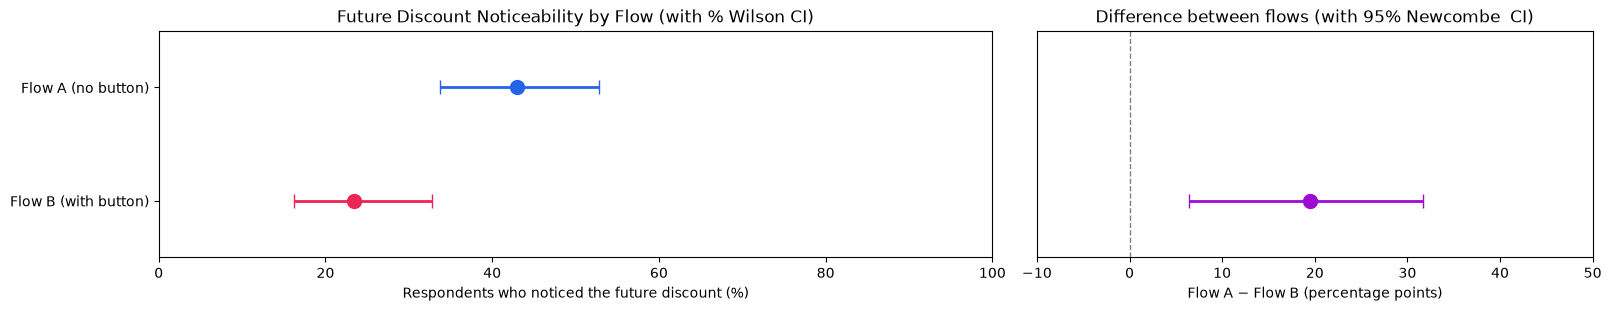

In [13]:
#мisualise the noticeability rates, the difference and their CIs
future_dsc_fig, future_dsc_axes = plt.subplots(ncols = 2, 
                                               figsize = (16,3),
                                               gridspec_kw = {'width_ratios': [1.5, 1]},
                                               layout = 'constrained')

#plot Flow A rate with its CI
future_dsc_axes[0].errorbar( x = future_dsc_noticed_rate_pct_flow_a,
                            y = 1, 
                            xerr = [[future_dsc_noticed_rate_pct_flow_a - future_dsc_noticed_ci_low_pct_flow_a],
                                    [future_dsc_noticed_ci_high_pct_flow_a - future_dsc_noticed_rate_pct_flow_a]],
                            fmt = 'o',
                            color = '#2563EB',
                            markersize=10,
                            capsize=5,
                            elinewidth=2
                            )

#plot Flow B rate with its CI
future_dsc_axes[0].errorbar( x = future_dsc_noticed_rate_pct_flow_b,
                            y = 2, 
                            xerr = [[future_dsc_noticed_rate_pct_flow_b - future_dsc_noticed_ci_low_pct_flow_b],
                                    [future_dsc_noticed_ci_high_pct_flow_b - future_dsc_noticed_rate_pct_flow_b]],
                            fmt = 'o',
                            color = "#EB2556",
                            markersize=10,
                            capsize=5,
                            elinewidth=2
                            )

#rate plots settings
future_dsc_axes[0].set (
    title = 'Future Discount Noticeability by Flow (with % Wilson CI)',
    xlabel='Respondents who noticed the future discount (%)',
    yticks=[1, 2],
    yticklabels=future_dsc_flow_a_b,
    xlim = (0, 100),
    ylim = (2.5, 0.5)
)

future_dsc_axes[1].errorbar( x = future_dsc_delta_pp,
                            y = 1, 
                            xerr = [[future_dsc_delta_pp - future_dsc_delta_ci_low*100],
                                    [future_dsc_delta_ci_high*100 - future_dsc_delta_pp]],
                            fmt = 'o',
                            color = "#9F0AD1",
                            markersize=10,
                            capsize=5,
                            elinewidth=2
                            )

#difference plots settings
future_dsc_axes[1].set (
    title = 'Difference between flows (with 95% Newcombe  CI)',
    xlabel='Flow A − Flow B (percentage points)',
    yticks=[],
    xlim = (-10, 50),
    ylim = (0.5, 2.5)
)

# Mark no difference between flows
future_dsc_axes[1].axvline(
    x=0,
    color='gray',
    linestyle='--',
    linewidth=1
)

plt.show()

**Interim Finding**

**Flow A (no button) demonstrates higher prompted future-discount noticeability than Flow B (with the “Agree and close” button): 43.00% vs 23.47%, a difference of +19.53 percentage points (95% Newcombe CI: +6.41 to +31.73 pp). The difference is statistically significant (two-sided two-proportion z-test, z = 2.91, p = 0.0036).**  
The confidence interval excludes zero but remains wide, indicating uncertainty about the size of Flow A's advantage.
*Note: This result does not establish an effect on actual repeat-payment behavior.*

The observed direction is opposite to the initial hypothesis that clicking "Agree and close" would encourage more deliberate processing
of the offer and improve recall. 
One possible explanation* is habitual pop-up dismissal ("cookie-banner blindness"): users may click "Agree and close" without reading the offer. In Flow B, this action also removes the reminder from the final payment confirmation screen, reducing opportunities to notice it.
*This behavioral explanation remains a hypothesis. The comparison does not isolate habitual dismissal from the effect of fewer reminder exposures.* 